# Сверточная сеть
В этом ноутбуке мы расширим предыдущий и создадим первую сверточную сеть

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [2]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist)


In [3]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [4]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [5]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

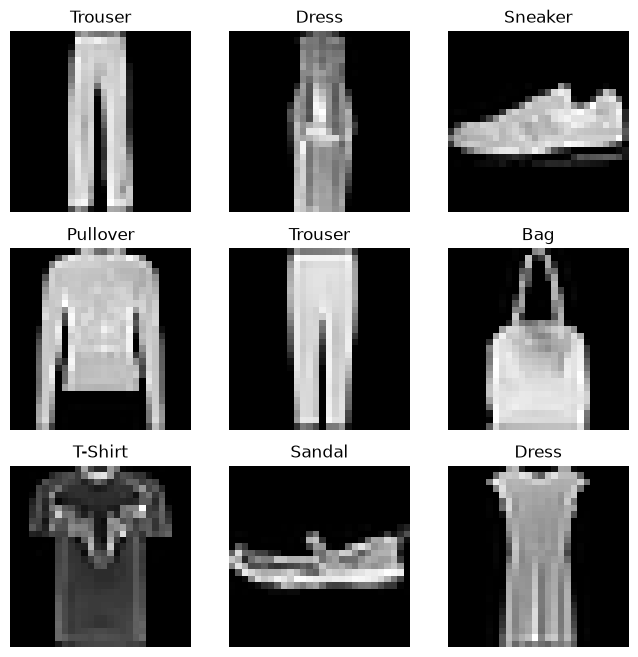

In [6]:
plot_samples(train_data, labels_map, cols=3, rows=3)

In [7]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


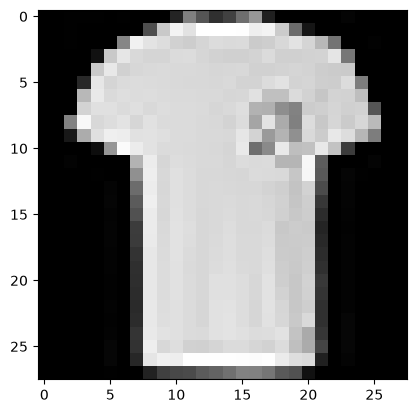

Label: 0


In [8]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [9]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using {device} device")

Using mps device


Теперь создадим класс модели и интстанциируем её. В данном случае это простая сверточная сеть: изображение проходит через блоки из сверток `nn.Conv2d` с batch-нормализацией (`nn.BatchNorm2d`) и активацией (`nn.ReLU`), а затем карта признаков разворачивается в вектор и подается в линейную голову `nn.Linear`, выдающую логиты для 10 классов. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.


### Архитектура модели

Схема ниже показывает названия слоев и размер выхода каждого слоя (для одного изображения):

![diagram](../images/simple_cnn.png)

In [10]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            # your code
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.head = nn.Linear(16*28*28, 10)

    def forward(self, x):
        x = self.base(x)
        # Необходимо превратить вход в вектор, чтобы можно было применить линейный слой

        x = x.view(x.size(0), -1)
        logits = self.head(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (head): Linear(in_features=12544, out_features=10, bias=True)
)


Часто вместо решейпа перед головой используют пулинг. Это специальный слой, который накладывается на вход и позволяет получить его преобразование (max, avg) без весов:
![alt text](..\images\max_pool.png "Stride=1, padding=0")

Если сделать MaxPool2d или AvgPool2d с размером ядра, равным размеру входа, то получится вектор такого же размера, как исходное число каналов. Однако, все равно придется добавить дополнительное измерение.

**Задание**: Измените модель, используя MaxPool или AvgPool вместо view(). Сравните результаты.

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [12]:
def train(dataloader, model, loss_fn, optimizer, verbose=True):
    """Одна эпоха обучения. Возвращает средний loss по эпохе (для трекинга лучшего значения)."""
    size = len(dataloader.dataset)
    model.train()
    total_loss = 0
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        # Compute prediction error
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        if verbose and batch_idx % 300 == 0:
            loss, current = loss.item(), (batch_idx + 1) * len(inputs)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    return total_loss / len(dataloader)

In [13]:
def test(dataloader, model, loss_fn, num_classes=10, verbose=True):
    """Возвращает loss, accuracy и macro-усреднённые precision/recall на dataloader."""
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0
    # confusion[i, j] — сколько объектов класса i предсказано как j
    confusion = torch.zeros(num_classes, num_classes, dtype=torch.long)
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            pred_labels = preds.argmax(1)
            num_correct += (pred_labels == targets).type(torch.float).sum().item()
            pairs = targets.cpu() * num_classes + pred_labels.cpu()
            confusion += torch.bincount(pairs, minlength=num_classes**2).view(num_classes, num_classes)
    test_loss /= num_batches
    accuracy = num_correct / size
    tp = confusion.diag().float()
    precision = (tp / confusion.sum(0).clamp(min=1)).mean().item()  # среди предсказанных как класс c
    recall = (tp / confusion.sum(1).clamp(min=1)).mean().item()  # среди настоящих объектов класса c
    if verbose:
        print(
            f"Test: accuracy {100 * accuracy:>0.1f}%, precision {100 * precision:>0.1f}%, "
            f"recall {100 * recall:>0.1f}%, avg loss {test_loss:>8f}"
        )
    return {"loss": test_loss, "accuracy": accuracy, "precision": precision, "recall": recall}

Задание: Добавьте метрики precision и recall для проверки

In [14]:
epochs = 10
best = {"train loss": float("inf"), "test loss": float("inf")}
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    # вызовите функции обучения и валидации
    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    metrics = test(test_dataloader, model, loss_fn)
    best["train loss"] = min(best["train loss"], train_loss)
    best["test loss"] = min(best["test loss"], metrics["loss"])
best

Epoch 1
-------------------------------


loss: 2.393111  [   64/60000]


loss: 0.698445  [19264/60000]


loss: 0.492418  [38464/60000]


loss: 0.519324  [57664/60000]


...

loss: 0.255461  [19264/60000]


loss: 0.237661  [38464/60000]


loss: 0.369519  [57664/60000]


Test: accuracy 89.3%, precision 89.4%, recall 89.3%, avg loss 0.298524


{'train loss': 0.24433088819704837, 'test loss': 0.2937727793576611}

### Задание: пулинг вместо `view()`

Заменяем «вытягивание» карты `16 × 28 × 28` в вектор длины 12544 на глобальный пулинг с ядром во всю карту
(`MaxPool2d(28)` / `AvgPool2d(28)`): от каждого канала остаётся одно число, получается `[B, 16, 1, 1]`.
Затем `flatten` убирает лишние измерения, и голова становится `Linear(16, 10)`.

Чтобы сравнение было честным и не слишком долгим, все три варианта обучаем одинаково: Adam, `lr=1e-3`, 5 эпох, один сид.

In [15]:
def fit(model, optimizer, epochs, train_loader=train_dataloader, test_loader=test_dataloader):
    """Обучает модель и возвращает метрики на тесте после каждой эпохи."""
    history = []
    for t in range(epochs):
        train_loss = train(train_loader, model, loss_fn, optimizer, verbose=False)
        metrics = test(test_loader, model, loss_fn, verbose=False)
        history.append({"train loss": train_loss, **{f"test {k}": v for k, v in metrics.items()}})
        print(f"epoch {t + 1:2d}: train loss {train_loss:.4f}, test loss {metrics['loss']:.4f}, "
              f"test accuracy {metrics['accuracy']:.1%}")
    return history

In [16]:
class PooledCNN(nn.Module):
    def __init__(self, pool):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.pool = pool
        self.head = nn.Linear(16, 10)

    def forward(self, x):
        x = self.pool(self.base(x))  # [B, 16, 28, 28] -> [B, 16, 1, 1]
        return self.head(x.flatten(1))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


variants = {
    "view()": NeuralNetwork,
    "MaxPool2d(28)": lambda: PooledCNN(nn.MaxPool2d(28)),
    "AvgPool2d(28)": lambda: PooledCNN(nn.AvgPool2d(28)),
}
pool_results = {}
for name, make_model in variants.items():
    print(name)
    torch.manual_seed(0)
    m = make_model().to(device)
    history = fit(m, torch.optim.Adam(m.parameters(), lr=1e-3), epochs=5)
    pool_results[name] = {"параметров": n_params(m), **history[-1]}

pd.DataFrame(pool_results).T.round(4)

view()


epoch  1: train loss 0.3846, test loss 0.3004, test accuracy 89.3%


epoch  2: train loss 0.2454, test loss 0.2837, test accuracy 89.9%


epoch  3: train loss 0.2017, test loss 0.3003, test accuracy 89.7%


epoch  4: train loss 0.1704, test loss 0.2621, test accuracy 91.0%


...

epoch  2: train loss 1.0077, test loss 0.9069, test accuracy 72.8%


epoch  3: train loss 0.8339, test loss 0.8208, test accuracy 73.3%


epoch  4: train loss 0.7394, test loss 0.7682, test accuracy 73.9%


epoch  5: train loss 0.6799, test loss 0.7410, test accuracy 73.4%


,параметров,train loss,test loss,test accuracy,test precision,test recall
view(),130490.0,0.1469,0.2800,0.9049,0.9052,0.9049
MaxPool2d(28),5210.0,0.5690,0.5835,0.7887,0.7916,0.7887
AvgPool2d(28),5210.0,0.6799,0.7410,0.7337,0.7553,0.7337


**Выводы.** Пулинг вместо `view()` сильно ухудшил качество: 78.9 % (max) и 73.4 % (avg) против 90.5 % за те же 5 эпох.
В этой сети всего две свёртки 3×3, рецептивное поле каждого выхода только 5×5 пикселей. После глобального пулинга от
каждого из 16 каналов остаётся одно число: «где-то на картинке есть такой локальный паттерн». Информация о том,
*где* он находится, теряется, а для одежды форма и расположение важны. С `view()` голова получает все 12544 значения
и сама учитывает положение признаков.

Зато параметров в 25 раз меньше (5 210 против 130 490), и модель не зависит от размера входа. Глобальный пулинг хорошо работает в
глубоких сетях, где к концу признаки уже «знают» про всю картинку (как в своей модели ниже). MaxPool здесь лучше AvgPool:
максимум сохраняет сильный локальный отклик, а среднее размывает его по всей карте.

Осталось сохранить модель для дальнейшего использования.

In [17]:
torch.save(model.state_dict(), "simple_cnn.pth")

Задание: придумайте свою собственную модель, на следующем занятии сравнимся, у кого получилось достичь наилучших результатов.

Своя модель: три блока «conv-BN-ReLU ×2 + MaxPool» (28 → 14 → 7 → 3), число каналов растёт 32 → 64 → 128,
в конце глобальный average pooling, Dropout и линейная голова. Пулинг между блоками увеличивает рецептивное
поле: последние свёртки видят почти всю картинку, а не окно 5×5, как в базовой модели.
Обучение: AdamW + OneCycleLR, 10 эпох.

In [18]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.MaxPool2d(2),
    )


class MyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 32), conv_block(32, 64), conv_block(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):
        return self.head(self.features(x))


EPOCHS = 10
train_loader_128 = DataLoader(train_data, batch_size=128, shuffle=True)
torch.manual_seed(0)
my_model = MyCNN().to(device)
optimizer = torch.optim.AdamW(my_model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-3, total_steps=EPOCHS * len(train_loader_128)
)


def train_one_cycle(dataloader, model, loss_fn, optimizer, verbose=False):
    # тот же train, но OneCycleLR шагает после каждого батча, а не после эпохи
    model.train()
    total = 0
    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        loss = loss_fn(model(inputs), targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total += loss.item()
    return total / len(dataloader)


print(f"параметров: {n_params(my_model)}")
for t in range(EPOCHS):
    train_loss = train_one_cycle(train_loader_128, my_model, loss_fn, optimizer)
    metrics = test(test_dataloader, my_model, loss_fn, verbose=False)
    print(f"epoch {t + 1:2d}: train loss {train_loss:.4f}, test accuracy {metrics['accuracy']:.1%}")
print()
my_metrics = test(test_dataloader, my_model, loss_fn)

параметров: 288618


epoch  1: train loss 0.6229, test accuracy 83.9%


epoch  2: train loss 0.3251, test accuracy 87.3%


epoch  3: train loss 0.2678, test accuracy 90.4%


epoch  4: train loss 0.2293, test accuracy 91.4%


...

epoch  7: train loss 0.1383, test accuracy 92.6%


epoch  8: train loss 0.1057, test accuracy 93.0%


epoch  9: train loss 0.0735, test accuracy 93.8%


epoch 10: train loss 0.0537, test accuracy 93.9%



Test: accuracy 93.9%, precision 93.9%, recall 93.9%, avg loss 0.184300


**Итог:** 93.9 % на тесте (precision и recall тоже 93.9 %) против 89.3 % у базовой модели с SGD (10 эпох) и 90.5 % у неё же с Adam.
При этом параметров в 2.2 раза больше, но вся модель меньше 300 тыс. весов. Помогли пулинг между блоками (большое
рецептивное поле, после чего глобальный average pooling уже не вредит), BatchNorm, Dropout перед головой и OneCycleLR.
Train loss к концу 0.05 при test loss 0.18, то есть модель уже заметно переобучается. Дальше стоило бы добавить
аугментации (сдвиги, отражения) или увеличить Dropout.